### Laboratorium 3 - zadania

In [15]:
import os

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.segmentation import mark_boundaries, slic

In [16]:
from scipy.ndimage import binary_fill_holes, distance_transform_edt
from skimage.filters import threshold_multiotsu
from skimage.segmentation import find_boundaries

%config InlineBackend.figure_formats = ['jpeg']  # zdjęcia z nakładkami w PNG ważą kilka MB
plt.rcParams['figure.dpi'] = 72

def show_grid(images, titles, ncols=None, size=4, cmap=None, **kw):
    ncols = ncols or len(images)
    nrows = -(-len(images) // ncols)
    h, w = images[0].shape[:2]
    _, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * h / w + 0.7 * nrows), squeeze=False, constrained_layout=True)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, img, title in zip(axes.ravel(), images, titles):
        ax.imshow(img, cmap=cmap, **kw); ax.set_title(title)
    plt.show()

def class_hist(seg, gt):
    """Dla każdego segmentu: liczba pikseli tła i obiektu (wzorzec binarny)."""
    return np.bincount(seg.ravel() * 2 + gt.ravel(), minlength=2 * (seg.max() + 1)).reshape(-1, 2)

def minority(seg, gt):
    h = class_hist(seg, gt)
    return h.min(1) / np.maximum(h.sum(1), 1)

def leak(seg, gt):
    return class_hist(seg, gt).min(1).sum() / gt.size

def mixed(seg, gt, tol=0.05):
    h = class_hist(seg, gt)
    h = h[h.sum(1) > 0]
    return (h.min(1) / h.sum(1) > tol).mean()

TOL = 2

def boundary_recall(seg, gt):
    near = cv2.dilate(find_boundaries(seg).astype(np.uint8), np.ones((2 * TOL + 1, 2 * TOL + 1), np.uint8)) > 0
    b = find_boundaries(gt)
    return (b & near).sum() / b.sum()

def scores(seg, gt):
    return dict(n=len(np.unique(seg)), leak=leak(seg, gt), mixed=mixed(seg, gt), br=boundary_recall(seg, gt))

def describe(seg, gt):
    s = scores(seg, gt)
    return f'{s["n"]} segm., leak {100 * s["leak"]:.2f}%, niejednolite {100 * s["mixed"]:.0f}%'

def overlay_mixed(img, seg, gt, tol=0.05):
    rgb = img if img.ndim == 3 else np.dstack([img] * 3)
    out = mark_boundaries(rgb, seg, color=(1, 1, 0))
    bad = (minority(seg, gt) > tol)[seg]
    out[bad] = 0.5 * out[bad] + 0.5 * np.array([1, 0, 0])
    return out

#### Zadanie 1

Dane są obrazy `tabby` i `caries` ([źródło](https://universe.roboflow.com/niu-workespeis/caries-xlrql/dataset/2)). Wykonaj dla nich segmentację przy użyciu algorytmu SLIC. Celem jest uzyskanie **jednolitych**  superpikseli, a więc zawierających tylko fragmenty obiektów lub tylko tła (a nie jednego i drugiego naraz). Przeanalizuj zachowanie algorytmu dla różnej liczby superpikseli i parametru sigma.

Zwróć uwagę, że wynikiem działania scikitowej implementacji SLIC - [`skimage.segmentation.slic`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.slic) - (podobnie jak wielu innych algorytmów klasyfikacyjnych) jest obraz typu `np.int64` przyporządkowujący każdemu pikselowi obrazu wejściowego indeks superpiksela. Takiej reprezentacji oczekuje też funkcja [`mark_boundaries`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.mark_boundaries).

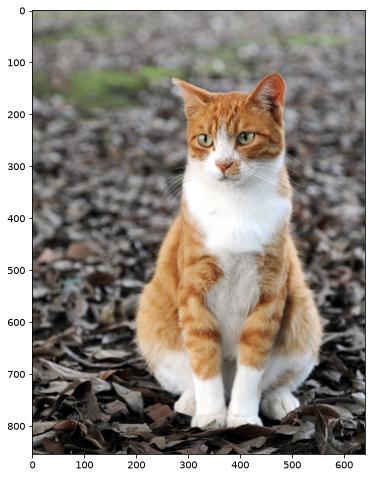

In [17]:
_ = cv2.imread('tabby.jpg')[..., ::-1]
tabby = cv2.resize(_, dsize=None, fx=0.3, fy=0.3)
plt.subplots(1,1,figsize=(8,8))[1].imshow(tabby);

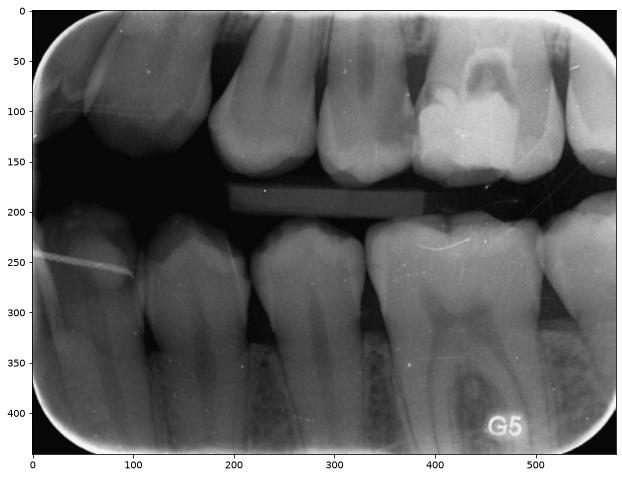

In [18]:
caries = cv2.imread('roboflow-caries-117.jpg')[..., 0]
plt.subplots(1,1,figsize=(12,8))[1].imshow(caries, cmap='gray');

Rozwiązanie:

**1.0 Wzorce obiekt/tło** (do liczbowej oceny jednolitości superpikseli).
- `tabby`: GrabCut z prostokątem wokół kota, z wyniku zostaje największa składowa z wypełnionymi dziurami (oczy).
- `caries`: trzy klasy jasności wyznaczone metodą Otsu (`threshold_multiotsu`) po medianie 7×7: ciemne szczeliny i tło, ząb i kość, szkliwo i wypełnienie. Obiekt to dwie jaśniejsze klasy, a tło to ciemne szczeliny. Wzorzec jest więc „jasnościowy” i nie odróżnia korzenia od kości.

Miary dla podziału na segmenty:
- **leak**: odsetek pikseli obrazu, które w swoim segmencie należą do klasy mniejszościowej. To błąd, którego nie da się uniknąć, jeśli każdy segment w całości przypiszemy do obiektu albo do tła. 0% oznacza, że wszystkie segmenty są jednolite.
- **niejednolite**: odsetek segmentów, w których klasa mniejszościowa przekracza 5% pola. Takie segmenty są na obrazach zabarwione na czerwono.
- **boundary recall**: odsetek konturu wzorca, który ma granicę segmentu w promieniu 2 px.

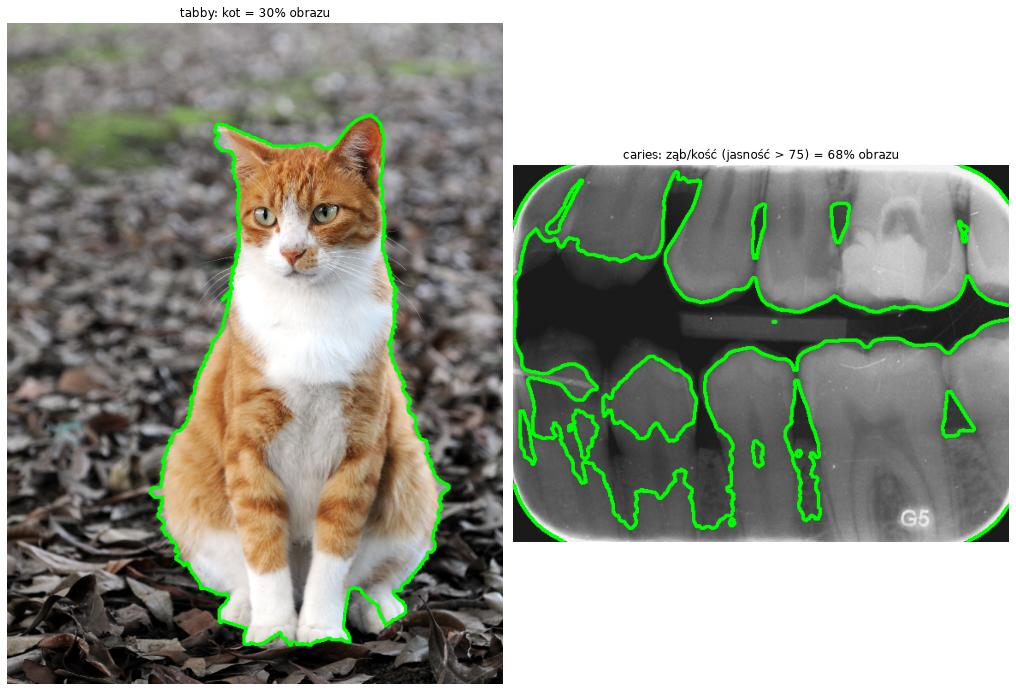

In [19]:
mask = np.zeros(tabby.shape[:2], np.uint8)
cv2.grabCut(tabby[..., ::-1].copy(), mask, (170, 105, 440, 740), np.zeros((1, 65)), np.zeros((1, 65)), 8, cv2.GC_INIT_WITH_RECT)
_, lab, stats, _ = cv2.connectedComponentsWithStats(np.isin(mask, [cv2.GC_FGD, cv2.GC_PR_FGD]).astype(np.uint8))
gt_tabby = binary_fill_holes(lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])).astype(int)

caries_med = cv2.medianBlur(caries, 7)
t_dark, t_bright = threshold_multiotsu(caries_med, classes=3)
gt_caries = (caries_med > t_dark).astype(int)

def contour(img, gt):
    out = (img if img.ndim == 3 else np.dstack([img] * 3)).copy()
    out[cv2.dilate(find_boundaries(gt).astype(np.uint8), np.ones((3, 3), np.uint8)) > 0] = (0, 255, 0)
    return out

show_grid([contour(tabby, gt_tabby), contour(caries, gt_caries)],
          [f'tabby: kot = {100 * gt_tabby.mean():.0f}% obrazu', f'caries: ząb/kość (jasność > {t_dark:.0f}) = {100 * gt_caries.mean():.0f}% obrazu'], size=7)

**1.1 Skala `compactness` dla obrazu szarego.** Obraz kolorowy SLIC przelicza na Lab (L ∈ [0, 100]), a obraz szary ma zakres [0, 1]. Domyślne `compactness=10` jest więc dla `caries` ok. 100× za duże, bo odległość przestrzenna całkowicie zagłusza różnice jasności. Wykres pokazuje przebieg `compactness` od skrajnie małej do domyślnej (n_segments = 400, σ = 1), a pod nim podział dla wartości skrajnych i wybranej. Dla `tabby` zostaje domyślne 10.

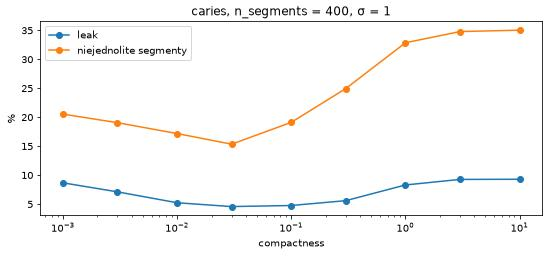

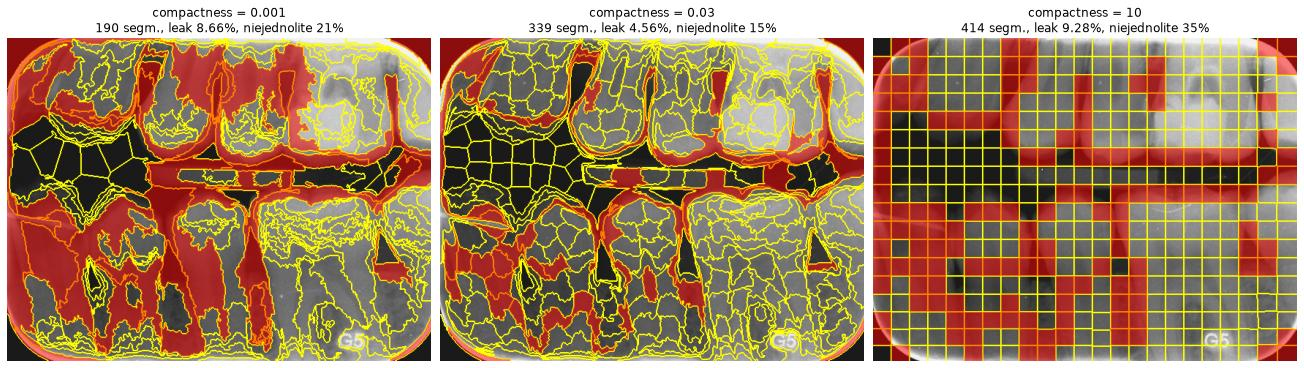

In [20]:
COMPACT = np.array([0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10])
comp = [slic(caries, n_segments=400, sigma=1, compactness=c, channel_axis=None, start_label=1) for c in COMPACT]
comp_scores = [scores(s, gt_caries) for s in comp]
_, ax = plt.subplots(figsize=(9, 3.5))
for key, label in [('leak', 'leak'), ('mixed', 'niejednolite segmenty')]:
    ax.semilogx(COMPACT, [100 * s[key] for s in comp_scores], 'o-', label=label)
ax.set_xlabel('compactness'); ax.set_ylabel('%'); ax.legend(); ax.set_title('caries, n_segments = 400, σ = 1'); plt.show()

C_CARIES = COMPACT[np.argmin([s['leak'] + s['mixed'] for s in comp_scores])]
picked = [0.001, C_CARIES, 10]
show_grid([overlay_mixed(caries, comp[list(COMPACT).index(c)], gt_caries) for c in picked],
          [f'compactness = {c}\n{describe(comp[list(COMPACT).index(c)], gt_caries)}' for c in picked], size=6)

**1.2 Liczba superpikseli × σ.** Pełna siatka: `n_segments` od 10 do 3200 i σ od 0 do 12. Pod wartością `n_segments` na osi X podana jest faktyczna liczba superpikseli (średnia po σ), bo `n_segments` to tylko przybliżenie. Gwiazdka oznacza najlepsze σ dla danego n.

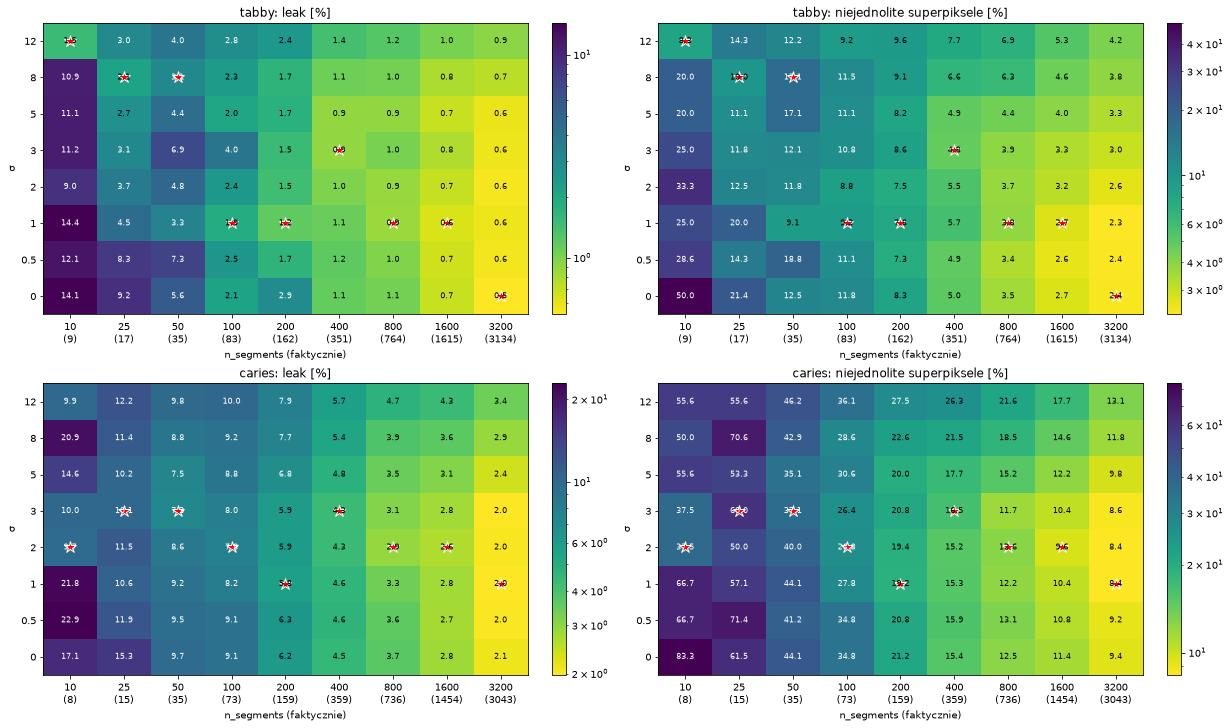

In [21]:
N_SEG = [10, 25, 50, 100, 200, 400, 800, 1600, 3200]
SIGMAS = [0, 0.5, 1, 2, 3, 5, 8, 12]
images = {'tabby': (tabby, gt_tabby, dict(compactness=10)),
          'caries': (caries, gt_caries, dict(compactness=C_CARIES, channel_axis=None))}

def run_slic(name, n, sigma):
    img, _, kw = images[name]
    return slic(img, n_segments=n, sigma=sigma, start_label=1, **kw)

sweep = {name: {key: np.array([[scores(run_slic(name, n, s), gt)[key] for n in N_SEG] for s in SIGMAS]) for key in ['n', 'leak', 'mixed', 'br']}
         for name, (_, gt, _) in images.items()}

_, axes = plt.subplots(2, 2, figsize=(17, 10), constrained_layout=True)
for row, (name, r) in zip(axes, sweep.items()):
    for ax, key, title in zip(row, ['leak', 'mixed'], ['leak [%]', 'niejednolite superpiksele [%]']):
        v = 100 * r[key]
        im = ax.imshow(v, origin='lower', aspect='auto', cmap='viridis_r', norm='log')
        for i in range(len(SIGMAS)):
            for j in range(len(N_SEG)):
                ax.text(j, i, f'{v[i, j]:.1f}', ha='center', va='center', fontsize=8, color='w' if v[i, j] > np.sqrt(v.min() * v.max()) else 'k')
        ax.plot(range(len(N_SEG)), r['leak'].argmin(0), 'r*', ms=12, mec='w')
        ax.set_xticks(range(len(N_SEG)), [f'{n}\n({k:.0f})' for n, k in zip(N_SEG, r['n'].mean(0))])
        ax.set_yticks(range(len(SIGMAS)), SIGMAS)
        ax.set_xlabel('n_segments (faktycznie)'); ax.set_ylabel('σ'); ax.set_title(f'{name}: {title}')
        plt.colorbar(im, ax=ax, fraction=0.046)
plt.show()

**Leak w funkcji faktycznej liczby superpikseli** dla σ = 0, najlepszego σ (najmniejsza średnia geometryczna leak dla n_segments ≥ 100) i skrajnego σ = 12. Kółkiem zaznaczony punkt pracy, czyli liczba superpikseli wybrana do dalszych porównań.

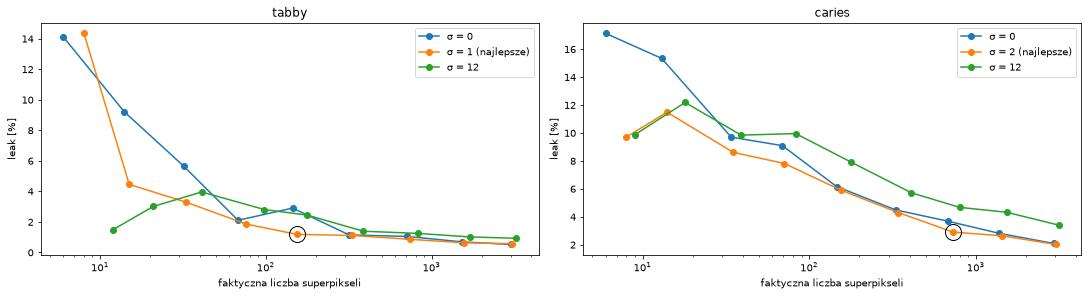

najlepsze σ (średnia geometryczna leak dla n_segments ≥ 100): {'tabby': 1, 'caries': 2}


In [22]:
USABLE = np.array(N_SEG) >= 100  # przy kilku-kilkudziesięciu superpikselach wynik zależy od przypadkowego ułożenia siatki
best_sigma = {name: SIGMAS[np.argmin(np.log(r['leak'][:, USABLE]).mean(1))] for name, r in sweep.items()}
WORK = {'tabby': 200, 'caries': 800}

_, axes = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True)
for ax, (name, r) in zip(axes, sweep.items()):
    for s in sorted({0, best_sigma[name], 12}):
        i = SIGMAS.index(s)
        ax.semilogx(r['n'][i], 100 * r['leak'][i], 'o-', label=f'σ = {s}' + (' (najlepsze)' if s == best_sigma[name] else ''))
    i, j = SIGMAS.index(best_sigma[name]), N_SEG.index(WORK[name])
    ax.plot(r['n'][i, j], 100 * r['leak'][i, j], 'o', ms=16, mfc='none', mec='k')
    ax.set_xlabel('faktyczna liczba superpikseli'); ax.set_ylabel('leak [%]'); ax.set_title(name); ax.legend()
plt.show()
print('najlepsze σ (średnia geometryczna leak dla n_segments ≥ 100):', best_sigma)

**1.3 Skrajności.** Górny wiersz: wpływ liczby superpikseli przy najlepszym σ (skrajnie mało, punkt pracy, skrajnie dużo). Dolny wiersz: wpływ σ przy liczbie z punktu pracy, na powiększonym wycinku trudnego fragmentu (głowa kota na tle liści, szczeliny i korzenie między zębami). Żółte linie to granice superpikseli, czerwone tło oznacza superpiksel niejednolity. Liczby w tytułach dotyczą całego obrazu, także na wycinkach.

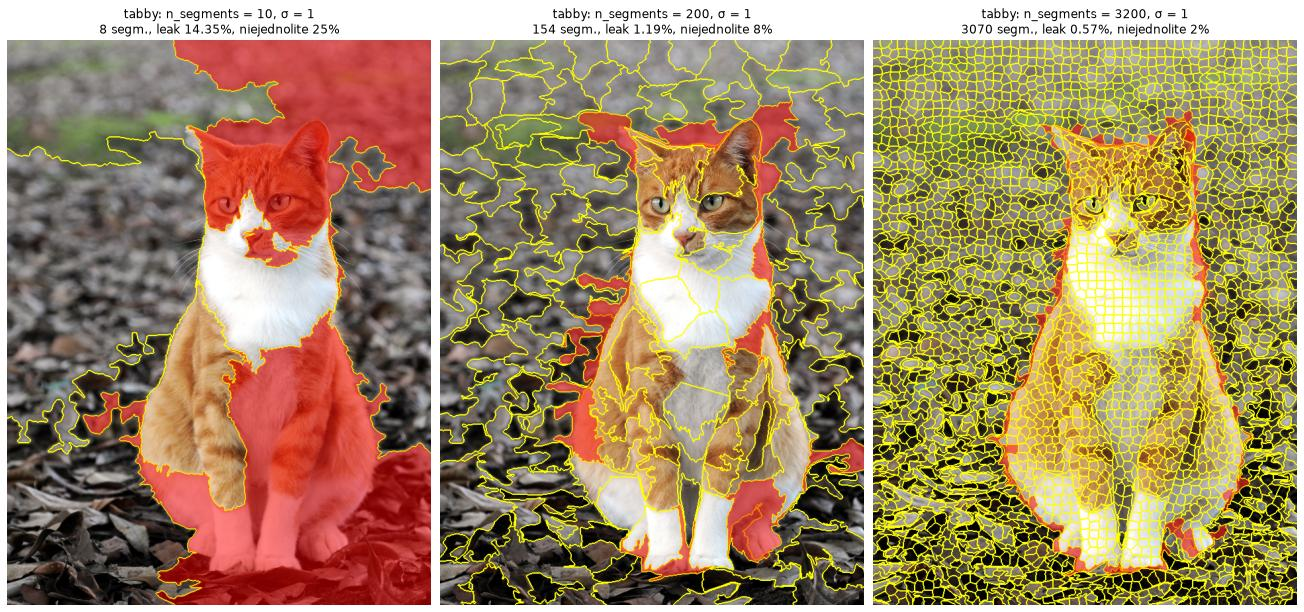

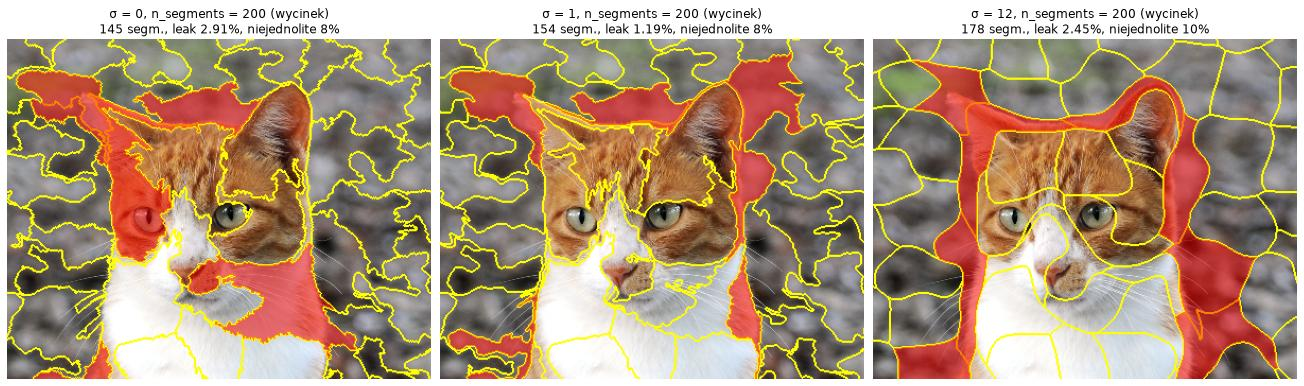

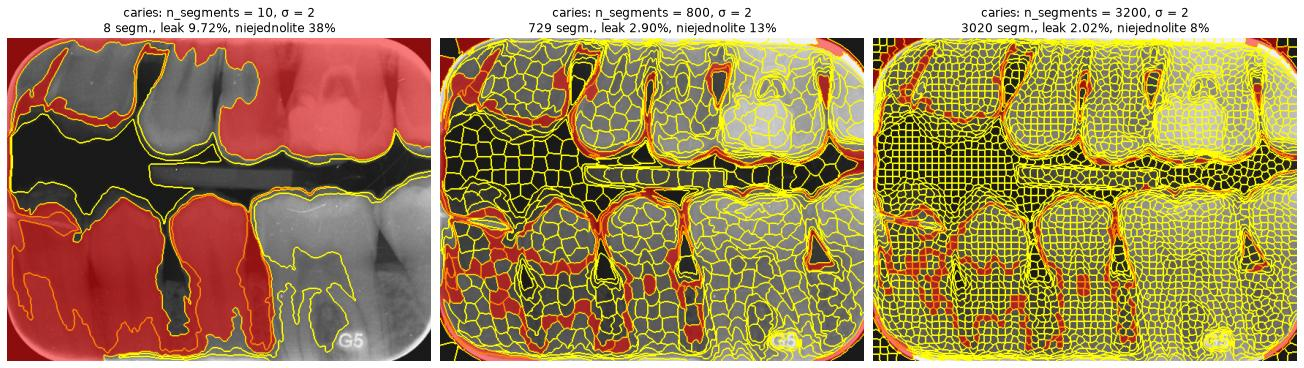

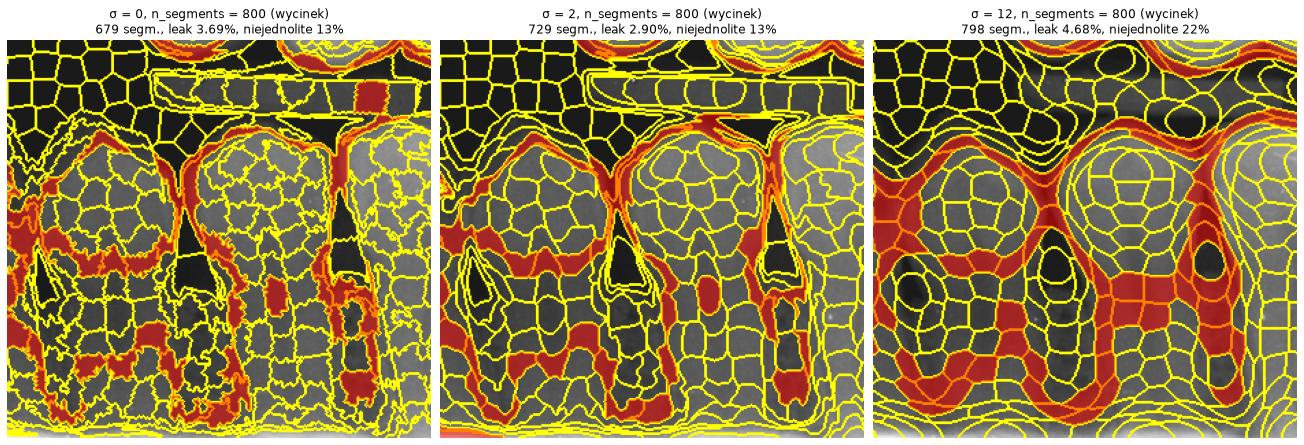

In [23]:
CROPS = {'tabby': (slice(80, 400), slice(200, 600)), 'caries': (slice(150, 441), slice(90, 400))}
for name, (img, gt, _) in images.items():
    segs = [run_slic(name, n, best_sigma[name]) for n in (10, WORK[name], 3200)]
    show_grid([overlay_mixed(img, s, gt) for s in segs],
              [f'{name}: n_segments = {n}, σ = {best_sigma[name]}\n{describe(s, gt)}' for n, s in zip((10, WORK[name], 3200), segs)], size=6)
    cy, cx = CROPS[name]
    sigmas = sorted({0, best_sigma[name], 12})
    segs = [run_slic(name, WORK[name], s) for s in sigmas]
    show_grid([overlay_mixed(img, s, gt)[cy, cx] for s in segs],
              [f'σ = {s}, n_segments = {WORK[name]} (wycinek)\n{describe(seg, gt)}' for s, seg in zip(sigmas, segs)], size=6)

**Wnioski (zad. 1)**
- **Liczba superpikseli to główny parametr.** `leak` maleje wraz z liczbą superpikseli, ale coraz wolniej.
  - `tabby` (σ = 1): 14% przy 8 superpikselach, 1.0% przy 154 i 0.6% przy 3070.
  - `caries` (σ = 2): 9.7% przy 8, 5.9% przy 159, 2.9% przy 729 i 2.0% przy 3020.

  Kolano wykresu wypada przy ok. 150–350 superpikselach dla `tabby` i ok. 700–800 dla `caries`. Dalszy zysk to dziesiąte części procenta, a superpiksele robią się tak małe, że przestają pełnić swoją rolę: przy 3200 mają średnio 170 px (`tabby`) i 80 px (`caries`).
- **Skrajnie mała liczba (8–35 superpikseli) daje wynik loteryjny.** Heatmapy w tych kolumnach nie mają żadnego trendu względem σ. Przykład: przy `n_segments` = 10 i σ = 12 kot został obrysowany prawie idealnie (leak 1.4%), bo przy dużym odstępie siatki S człon przestrzenny (m/S)·d_xy jest słaby i o przydziale decyduje kolor. Przy σ = 1 i tej samej liczbie superpikseli kot zlewa się z tłem (leak 14%, 25% superpikseli niejednolitych).
- **Zero się nie da osiągnąć.** Nawet przy 3200 superpikselach niejednolite zostają w wąskim pasie wzdłuż konturu: 2% superpikseli w `tabby` i 8% w `caries`.
  - `tabby`: problem sprawiają wąsy, sierść na brzegu i miejsca, gdzie rude futro sąsiaduje z brązowymi liśćmi (łapy, ucho).
  - `caries`: problem sprawiają szczeliny między korzeniami. Przejście ząb–szczelina jest łagodne, a wąskie szczeliny są węższe niż superpiksel.

  Dlatego `caries` potrzebuje ok. 5× więcej superpikseli niż `tabby` dla podobnej jakości.
- **σ ma dużo mniejszy wpływ niż liczba superpikseli.** Najlepsze σ (średnia geometryczna `leak` dla `n_segments` ≥ 100):
  - `tabby`: σ = 1 daje 0.89%, wobec 1.14% bez wygładzania i 1.45% przy σ = 12;
  - `caries`: σ = 2 daje 3.8%, wobec 4.2% bez wygładzania i 5.6% przy σ = 12.

  Bez wygładzania granice są postrzępione przez teksturę liści i szum RTG (wycinki: `tabby` 3.0% przy σ = 0 wobec 1.0% przy σ = 1; `caries` 3.7% wobec 2.9%). Skrajne σ = 12 zamienia superpiksele w gładkie „bąble”, które nie wchodzą w ucho ani w wąskie szczeliny. `leak` rośnie (`tabby` 2.3%, `caries` 4.7%, w tym 22% superpikseli niejednolitych), a boundary recall dla `tabby` przy 200 superpikselach spada z 92% do 48%. Przy bardzo dużej liczbie superpikseli σ prawie nie ma znaczenia (`tabby`, 3200: 0.51–0.71% dla σ ≤ 8).
- **`compactness` trzeba dopasować do skali obrazu szarego.** Domyślne 10 daje na `caries` siatkę kwadratów (leak 9.3%, 35% superpikseli niejednolitych). Optimum to 0.03 (4.6%, 15%). Skrajnie małe 0.001 daje poszarpane superpiksele i `leak` znowu rośnie do 8.7%.

#### Zadanie 2

Wykonaj segmentację wododziałową dla obrazów `tabby` i `caries` za pomocą funkcji [`cv2.watershed`](https://docs.opencv.org/4.x/d3/d47/group__imgproc__segmentation.html#ga3267243e4d3f95165d55a618c65ac6e1). Implementacja OpenCV przyjmuje dwa argumenty: obraz wejściowy (8-bit, 3 kanały) i obraz wyjściowy (32-bit, 1 kanał).

Uwaga: obraz wyjściowy musi zawierać oznaczenia początkowe segmentów (_markery_) - to znaczy, że musisz zacząć od przygotowania macierzy markerów. Poprawnie przygotowana macierz zawiera $N$ markerów, tj. pikseli oznaczonych liczbami całkowitymi od 1 do $N$, a wartość pozostałych pikseli wynosi 0. Piksele zerowe zostaną przyporządkowane do grup dookoła markerów.

Sugerowane metody przygotowania markerów (wybierz dwie i porównaj):
* równomierna siatka
* lokalne minima jasności
* manualnie wybrane centra (_segmentacja interaktywna_)

Rozwiązanie:

Wynik `cv2.watershed` zawiera linie wododziałów (−1, w tym ramka obrazu). Na potrzeby metryk z zad. 1 każdy taki piksel dostaje etykietę najbliższego segmentu. Markery:
- **siatka**: pojedyncze piksele co `step` px;
- **minima jasności**: obraz szary rozmyty Gaussem σ, minimum lokalne tam, gdzie piksel jest równy minimum w oknie k×k (`cv2.erode`), a płaskie plateau minimów są łączone w jeden marker.

In [24]:
def ws(img, markers):
    img3 = img if img.ndim == 3 else np.dstack([img] * 3)
    m = markers.astype(np.int32).copy()
    cv2.watershed(np.ascontiguousarray(img3), m)
    return m[tuple(distance_transform_edt(m <= 0, return_distances=False, return_indices=True))]

def grid_markers(shape, step):
    m = np.zeros(shape, np.int32)
    ys, xs = np.arange(step // 2, shape[0], step), np.arange(step // 2, shape[1], step)
    m[np.ix_(ys, xs)] = np.arange(1, len(ys) * len(xs) + 1).reshape(len(ys), len(xs))
    return m

def minima_markers(gray, sigma, k):
    g = cv2.GaussianBlur(gray, (0, 0), sigma) if sigma > 0 else gray
    return cv2.connectedComponents((g == cv2.erode(g, np.ones((k, k), np.uint8))).astype(np.uint8))[1]

gray = {'tabby': cv2.cvtColor(tabby, cv2.COLOR_RGB2GRAY), 'caries': caries}

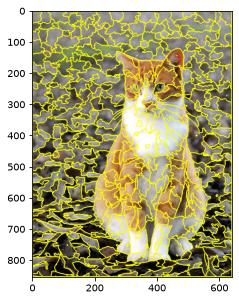

In [25]:
markers = grid_markers(tabby.shape[:2], 32)  # markery z siatki co 32 px (punkt pracy z 2.1)
cv2.watershed(tabby, markers)
plt.imshow(mark_boundaries(tabby, markers));

**2.1 Porównanie metod.** Przebieg `step` siatki (6–200 px) oraz σ ∈ {0, 1, 2, 4, 8} × k ∈ {3…41} dla minimów (linia dla każdego σ, wzdłuż linii rośnie k). Oś X: faktyczna liczba segmentów. Odniesienie: SLIC z zad. 1 przy najlepszym σ.

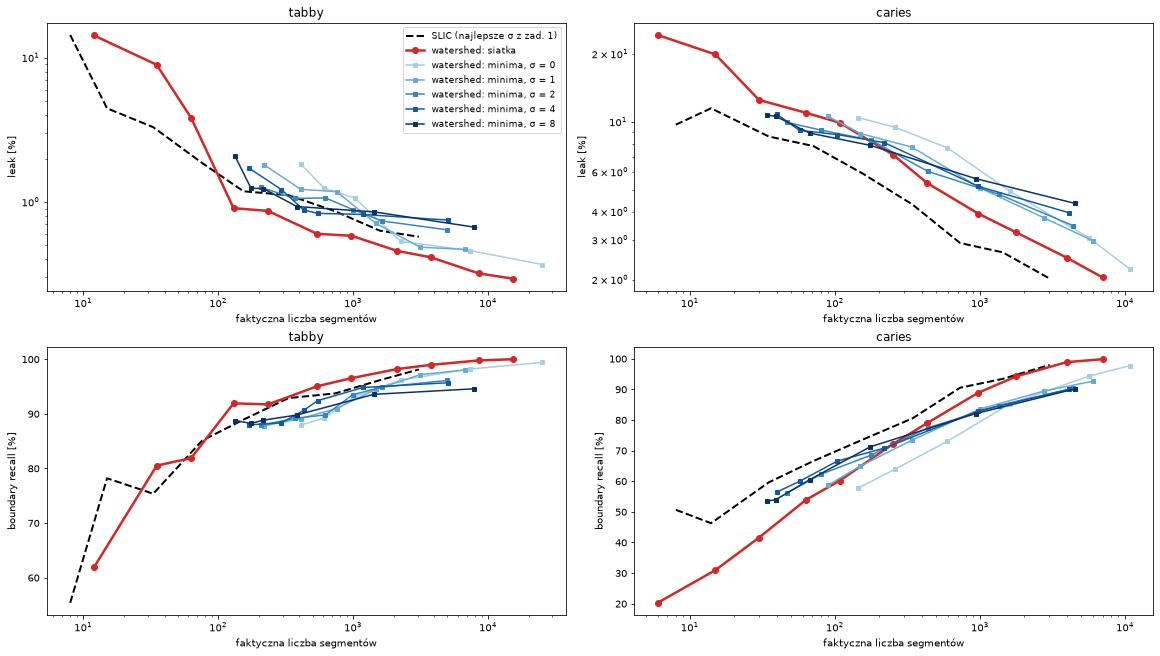

In [26]:
STEPS = [6, 8, 12, 16, 24, 32, 48, 64, 96, 128, 200]
MIN_SIGMAS, MIN_K = [0, 1, 2, 4, 8], [3, 5, 9, 15, 25, 41]
ws_grid = {name: [scores(ws(img, grid_markers(gt.shape, st)), gt) for st in STEPS] for name, (img, gt, _) in images.items()}
ws_min = {name: {s: [scores(ws(img, minima_markers(gray[name], s, k)), gt) for k in MIN_K] for s in MIN_SIGMAS} for name, (img, gt, _) in images.items()}

_, axes = plt.subplots(2, 2, figsize=(16, 9), constrained_layout=True)
for col, name in enumerate(images):
    r = sweep[name]; i = SIGMAS.index(best_sigma[name])
    for row, (key, ylabel) in enumerate([('leak', 'leak [%]'), ('br', 'boundary recall [%]')]):
        ax = axes[row, col]
        ax.semilogx(r['n'][i], 100 * r[key][i], 'k--', lw=2, label='SLIC (najlepsze σ z zad. 1)')
        ax.semilogx([s['n'] for s in ws_grid[name]], [100 * s[key] for s in ws_grid[name]], 'o-', lw=2.5, color='tab:red', label='watershed: siatka')
        for s, c in zip(MIN_SIGMAS, plt.cm.Blues(np.linspace(0.35, 1, len(MIN_SIGMAS)))):
            ax.semilogx([x['n'] for x in ws_min[name][s]], [100 * x[key] for x in ws_min[name][s]], 's-', ms=4, color=c, label=f'watershed: minima, σ = {s}')
        ax.set_xlabel('faktyczna liczba segmentów'); ax.set_ylabel(ylabel); ax.set_title(name)
        if key == 'leak':
            ax.set_yscale('log')
axes[0, 0].legend(fontsize=9); plt.show()

**2.2 Wizualizacja.** Górny wiersz: siatka (za mało markerów, punkt pracy, za dużo). Dolny wiersz: minima jasności (skrajnie dużo markerów przy σ = 0, k = 3, wartości dobrane, skrajnie mało przy σ = 8, k = 41). Niebieskie kropki to markery, czerwone tło oznacza segment niejednolity. CV to współczynnik zmienności pól segmentów (odchylenie standardowe / średnia), który mierzy nierównomierność podziału. „Markery na obiekcie” to odsetek markerów leżących na obiekcie wzorca (kot zajmuje 30% obrazu, ząb/kość 68%). Dobrane wartości minimów dają mniej więcej tyle segmentów co siatka w punkcie pracy.

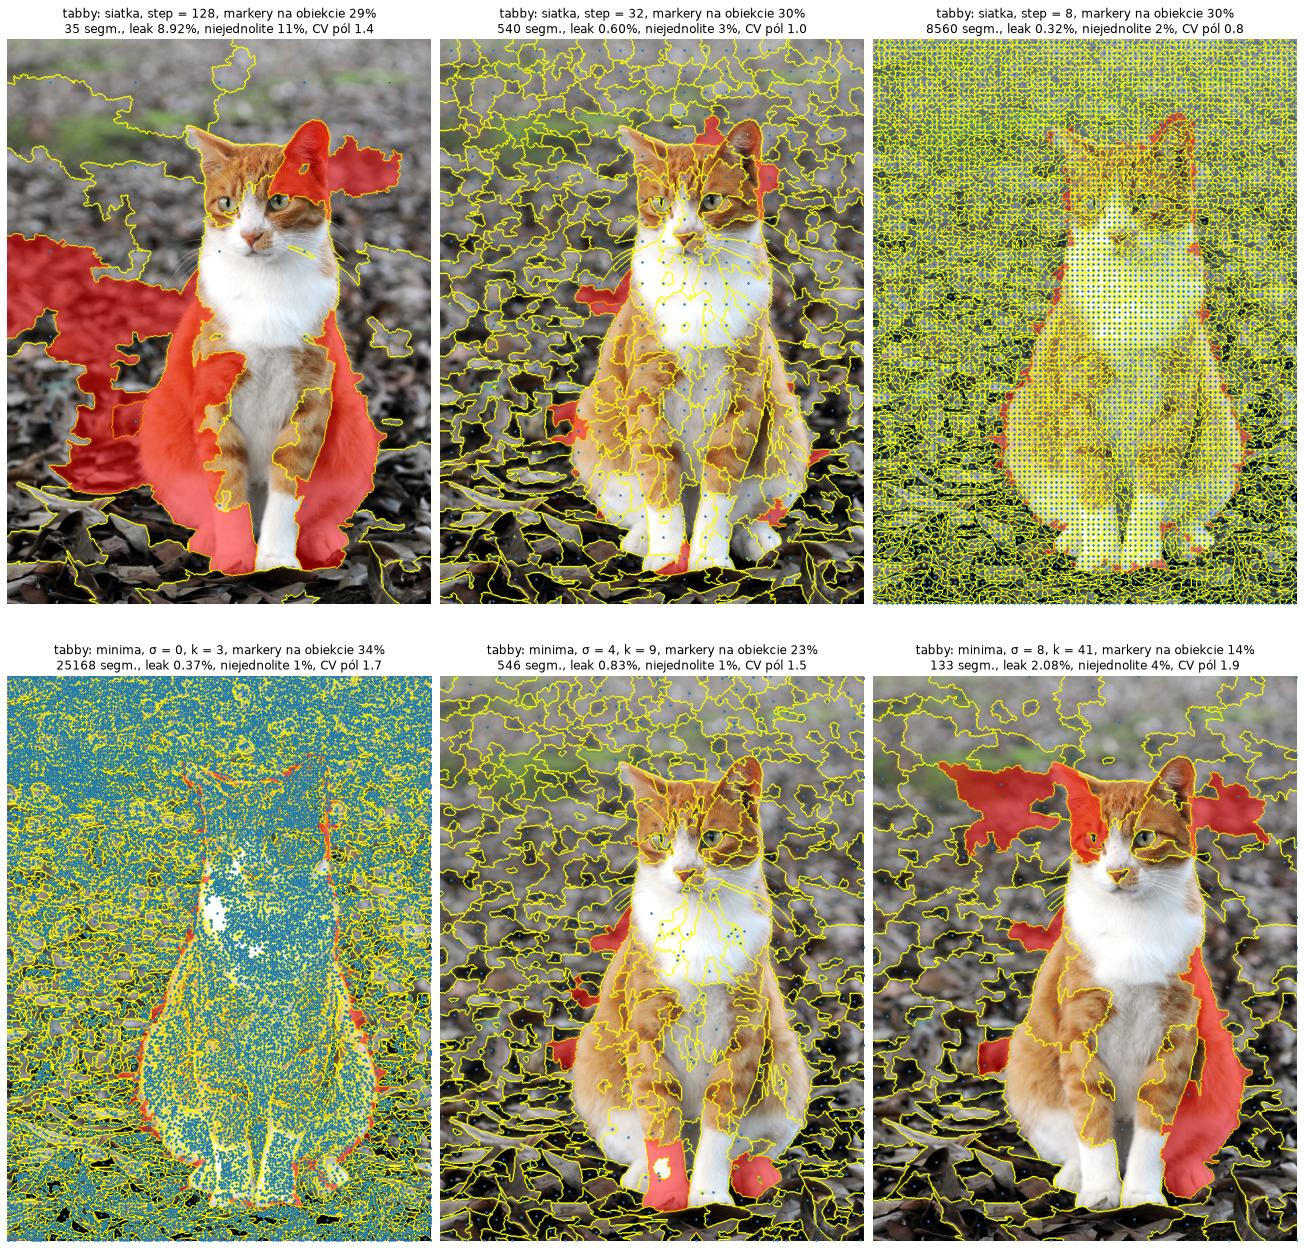

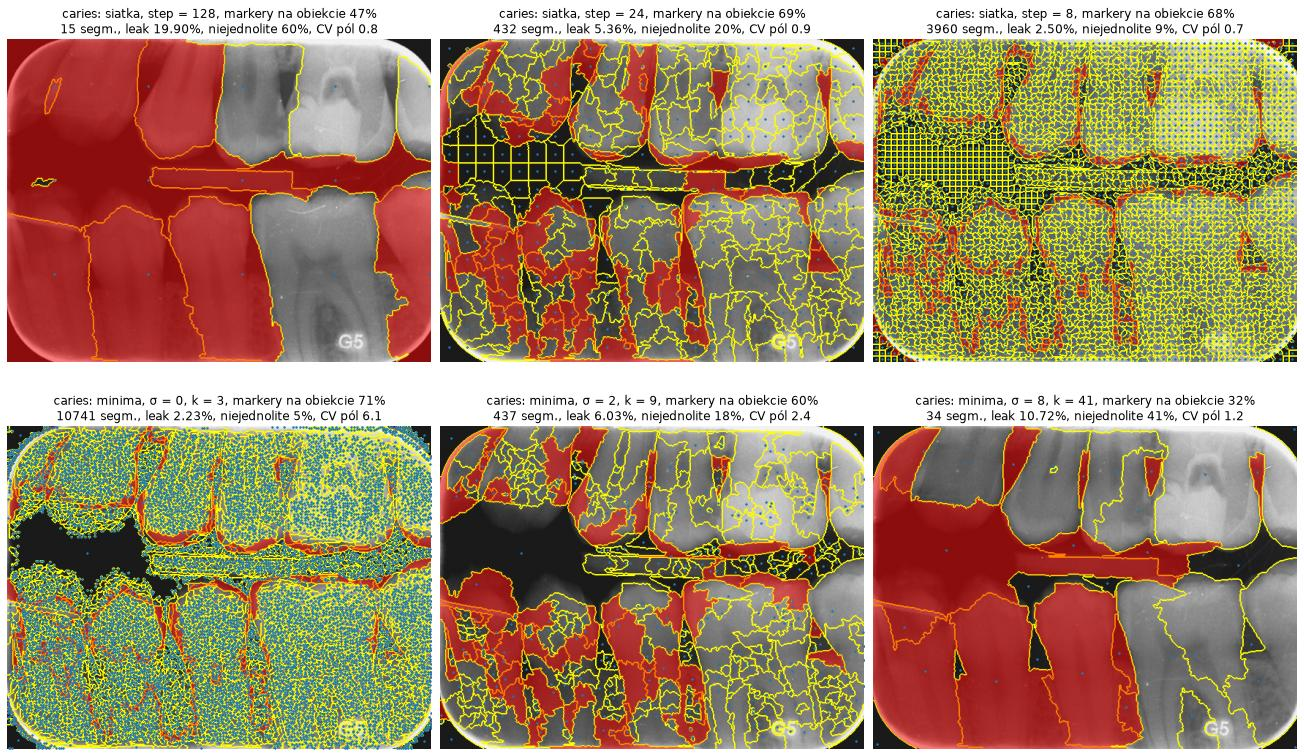

In [27]:
WS_SHOW = {'tabby': dict(steps=[128, 32, 8], minima=[(0, 3), (4, 9), (8, 41)]),
           'caries': dict(steps=[128, 24, 8], minima=[(0, 3), (2, 9), (8, 41)])}

def centers(markers):
    n = markers.max()
    ys, xs = np.nonzero(markers)
    cnt = np.bincount(markers[ys, xs], minlength=n + 1)[1:]
    return np.bincount(markers[ys, xs], xs, n + 1)[1:] / cnt, np.bincount(markers[ys, xs], ys, n + 1)[1:] / cnt

for name, (img, gt, _) in images.items():
    runs = [(f'siatka, step = {st}', grid_markers(gt.shape, st)) for st in WS_SHOW[name]['steps']]
    runs += [(f'minima, σ = {s}, k = {k}', minima_markers(gray[name], s, k)) for s, k in WS_SHOW[name]['minima']]
    h, w = gt.shape
    _, axes = plt.subplots(2, 3, figsize=(18, 2 * 6 * h / w + 1.6), constrained_layout=True)
    for ax, (title, mk) in zip(axes.ravel(), runs):
        seg = ws(img, mk)
        area = np.bincount(seg.ravel())[1:]; area = area[area > 0]
        ax.imshow(overlay_mixed(img, seg, gt)); ax.axis('off')
        cx, cy = centers(mk)
        ax.scatter(cx, cy, s=2, c='tab:blue')
        on_obj = gt[cy.round().astype(int), cx.round().astype(int)].mean()
        ax.set_title(f'{name}: {title}, markery na obiekcie {100 * on_obj:.0f}%\n{describe(seg, gt)}, CV pól {area.std() / area.mean():.1f}')
    plt.show()

**Wnioski (zad. 2)**
- **Watershed a SLIC zależy od obrazu.**
  - `tabby`: przy tej samej liczbie segmentów watershed z siatką ma mniejszy `leak` niż SLIC. Przy 234 segmentach jest to 0.64%, wobec 0.97% dla SLIC przy 162. Przy 972 segmentach jest to 0.45%, wobec 0.91% dla SLIC przy 764. Wododziały biegną dokładnie po krawędziach koloru, a SLIC wygładza granice członem zwartości.
  - `caries`: SLIC wygrywa w całym zakresie. Przy ok. 750–1000 segmentach SLIC ma 2.9%, siatka 3.9%, a minima 5.1–5.6%. Na zaszumionym zdjęciu RTG o niskim kontraście różnice między sąsiednimi pikselami są słabe, więc zalewanie przechodzi przez łagodne przejścia ząb–szczelina. Lokalne k-średnie w SLIC z σ = 2 są na szum odporniejsze.
  - Przy małej liczbie segmentów (< 100) watershed z siatką przegrywa na obu obrazach. Dla `tabby` przy 35 segmentach ma 8.9%, a SLIC 3.0%. Kilka markerów musi zalać duże obszary, a zalewanie z markera leżącego w tle łatwo „przelewa się” na obiekt.
- **Siatka czy minima jasności?** Przy tej samej liczbie segmentów siatka jest lepsza albo równa, a liczbę segmentów ustawia się nią wprost.
  - `tabby`: przy ok. 550 segmentach minima (σ = 4, k = 9) mają 0.58%, a siatka 0.72%. Przy ok. 1000 segmentach siatka ma 0.45%, a minima 0.58–0.80%.
  - `caries`: siatka wygrywa przy ponad 300 segmentach, np. 5.4% wobec 6.0% przy ok. 435 oraz 3.9% wobec 5.1–5.6% przy ok. 1000. Minima są nieznacznie lepsze dopiero przy ok. 100 segmentach (8.8% wobec 9.9%).
  - Minimów nie da się użyć do bardzo zgrubnego podziału: nawet przy σ = 8 i k = 41 zostaje 133 segmentów (`tabby`), a i tak mają one `leak` 1.8%, wobec 0.9% dla siatki przy 130.
- **Rozmieszczenie markerów wyjaśnia różnicę.**
  - Siatka pokrywa obraz równomiernie: odsetek markerów na obiekcie jest równy jego udziałowi w polu (ok. 30% dla `tabby` i 68% dla `caries`). Segmenty mają podobne pola (CV 0.7–1.0 od punktu pracy w górę).
  - Minima jasności z definicji leżą w ciemnych miejscach. W miarę wzrostu σ i k uciekają z jasnych obiektów. Na kocie leży 35% markerów przy σ = 0, k = 3, ale tylko 24% przy σ = 4, k = 9 i 14% przy σ = 8, k = 41. Na zębach odpowiednio 71%, 60% i 32%.
  - Jasne obszary (biała pierś kota, szkliwo, wypełnienie) dostają mało markerów i są zalewane z markerów w ciemnym sąsiedztwie. Powstają duże segmenty obejmujące ząb razem ze szczeliną: przy σ = 8, k = 41 aż 41% segmentów `caries` jest niejednolitych.
  - Pola segmentów są bardzo nierówne (CV 1.5–1.9 dla `tabby`, 2.4–6.1 dla `caries`). W teksturze liści i w szumie RTG powstaje masa drobnych segmentów, a czarna szczelina między szczękami to jedno płaskie plateau, czyli jeden marker i jeden ogromny segment. Ten segment jest akurat jednolity.
- **Skrajności:**
  - σ = 0, k = 3: każde minimum szumu staje się markerem (25 tys. segmentów dla `tabby`, 11 tys. dla `caries`). `leak` jest niski (0.38% i 2.2%), ale to już praktycznie segmentacja na poziomie pikseli.
  - Siatka co 128 px: 15–35 segmentów, które przecinają obiekty (`leak` 8.9% i 19.9%).
- **Podsumowanie:** dla tych obrazów lepsze są markery z siatki: przewidywalna liczba segmentów, równomierny podział i mniejszy lub równy `leak`. Minima jasności pasują do obiektów ciemnych na jasnym tle. Tu oba obiekty (kot, zęby) są jaśniejsze od tła, więc lepsze byłyby maksima jasności albo minima modułu gradientu.

---

#### Zadanie dodatkowe (dla chętnych, bez oceny)

Dla obrazu `tabby` wykonaj post-processing wybranej metody segmentacji by uzyskać dwa jednorodne obszary: jeden zawierający wyłącznie kota, drugi zawierający wyłącznie tło.

Można to zadanie potraktować jako binaryzację na poziomie superpikseli i zrealizować je za pomocą progowania. 
Można też potraktować je jako klasteryzację superpikseli i wykorzystać np. [`cv2.kmeans`](https://docs.opencv.org/4.x/d5/d38/group__core__cluster.html#ga9a34dc06c6ec9460e90860f15bcd2f88).  
Niezależnie od wybranej ścieżki, konieczne będzie:
1. dobranie odpowiednich (czyli jakich?) parametrów algorytmu segmentacji,
2. opisanie każdego z superpikseli za pomocą jakiejś *cechy/cech* (jakich?), opisującej semantykę rejonów, tak aby na tej podstawie dokonać klasyfikacji.

In [28]:
# zacznij od przygotowania macierzy wejściowej (data) reprezentującej superpiksele jako punkty danych